# 3. Quatre modèles candidats et choix du meilleur

| Modèle | Type | Pourquoi lui |
| --- | --- | --- |
| Isolation Forest | non supervisé | apprend le normal seul, isole ce qui est rare ; rapide, robuste au bruit |
| One-Class SVM | non supervisé | frontière du normal dans l'espace des features ; référence de la phase 2 |
| Random Forest | supervisé | apprend sur des attaques étiquetées ; robuste, explicable avec SHAP |
| XGBoost | supervisé | boosting, souvent le plus précis sur des données tabulaires ; explicable avec SHAP |

**Protocole.** Les non-supervisés apprennent sur les lignes normales des blocs d'entraînement ; les
supervisés sur toutes leurs lignes (normales et attaques). Le seuil d'alerte de chaque modèle est
choisi sur la **validation** (F1 maximal), puis appliqué tel quel au **test**.

In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]
import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.api.v1 import phase2
from app.core import paths

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"

In [2]:
df = pd.read_csv(tr.DATASET_PATH, parse_dates=["datetime"], keep_default_na=False)
df["garde"] = df["garde"].astype(str).str.lower().eq("true")
df, feats = tm.engineer(df)
episodes = json.load(open(EPISODES_PATH))

y = df["label"].to_numpy().astype(int)
split = df["split"].to_numpy()
garde = df["garde"].to_numpy()
train_all = np.where((split == "train") & ~garde)[0]
train_norm = train_all[y[train_all] == 0]
val_idx = np.where((split == "val") & ~garde)[0]
test_idx = np.where((split == "test") & ~garde)[0]
X = df[feats].to_numpy(float)
from sklearn.preprocessing import StandardScaler
X_s = StandardScaler().fit(X[train_norm]).transform(X)
print(f"train {len(train_all):,} lignes ({len(train_norm):,} normales) | val {len(val_idx):,} | test {len(test_idx):,}")

train 26,023 lignes (22,227 normales) | val 8,280 | test 8,280


## 3.1 Entraînement des quatre modèles

In [3]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from xgboost import XGBClassifier

scores = {}

iso = IsolationForest(n_estimators=300, max_samples=4096, random_state=SEED, n_jobs=-1).fit(X_s[train_norm])
scores["Isolation Forest"] = -iso.score_samples(X_s)          # plus grand = plus anormal

scores["One-Class SVM"], ocsvm_params = ts.ocsvm_scores(X_s, y, train_norm, val_idx)   # nu et gamma choisis sur la validation

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                            random_state=SEED, n_jobs=-1).fit(X[train_all], y[train_all])
scores["Random Forest"] = rf.predict_proba(X)[:, 1]

pos = int(y[train_all].sum())
xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=(len(train_all) - pos) / pos, eval_metric="logloss",
                    random_state=SEED, n_jobs=8, verbosity=0).fit(X[train_all], y[train_all])
scores["XGBoost"] = xgb.predict_proba(X)[:, 1]
print("4 modèles entraînés")

[   8.6s]   OCSVM : nu=0.01 gamma=0.001 (AUC val 0.7356)


4 modèles entraînés


## 3.2 Évaluation sur le test (répétition 0)

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

rows, preds = [], {}
for nom, s in scores.items():
    thr = phase2._best_f1_threshold(y[val_idx], s[val_idx])
    preds[nom] = s >= thr
    r = tr.pool([tr.count_run(preds[nom], df, test_idx, episodes, "test")])
    rows.append({"modèle": nom, "AUC": round(roc_auc_score(y[test_idx], s[test_idx]), 3),
                 "précision": r["precision"], "rappel": r["recall"], "F1": r["f1"],
                 "fausses alertes / h": r["fausses_alarmes_evenements_par_heure"],
                 "épisodes détectés": f"{r['episodes_detectes']}/{r['episodes']}",
                 "délai médian (min)": r["delai_median_min"]})
pd.DataFrame(rows).set_index("modèle")

,AUC,précision,rappel,F1,fausses alertes / h,épisodes détectés,délai médian (min)
modèle,,,,,,,
Isolation Forest,0.766,0.6461,0.3401,0.4456,11.44,6/6,10.3
One-Class SVM,0.785,0.5301,0.5012,0.5153,17.67,6/6,4.8
Random Forest,0.824,0.7775,0.4548,0.5739,3.37,6/6,2.1
XGBoost,0.774,0.6339,0.4296,0.5121,5.41,5/6,1.8


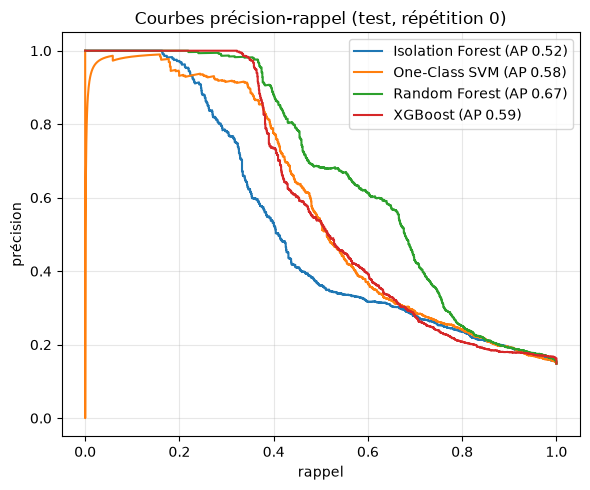

In [5]:
plt.figure(figsize=(6, 5))
for nom, s in scores.items():
    p, r, _ = precision_recall_curve(y[test_idx], s[test_idx])
    plt.plot(r, p, label=f"{nom} (AP {average_precision_score(y[test_idx], s[test_idx]):.2f})")
plt.xlabel("rappel"); plt.ylabel("précision"); plt.title("Courbes précision-rappel (test, répétition 0)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()

In [6]:
types = df["attack_type"].to_numpy()
par_scenario = {}
for nom, pred in preds.items():
    m = np.zeros(len(df), bool); m[test_idx] = True
    par_scenario[nom] = {sc: round(100 * (pred & m & (types == sc)).sum() / max(1, (m & (types == sc)).sum()), 1)
                         for sc in tr.ATTACK_NAMES if (m & (types == sc)).any()}
pd.DataFrame(par_scenario).rename_axis("% des lignes d'attaque signalées (test, répétition 0)")

,Isolation Forest,One-Class SVM,Random Forest,XGBoost
"% des lignes d'attaque signalées (test, répétition 0)",,,,
MITM_gel,93.7,96.2,95.8,95.8
MITM_rejeu,0.5,0.9,15.6,9.9
Injection_nominale,19.7,72.3,94.8,94.8
Injection_biais_0.5,0.5,18.7,39.0,31.3
Injection_biais_1.0,3.6,18.8,6.7,0.0
Injection_biais_2.0,89.4,96.9,6.2,12.5


Une seule répétition ne contient que 4 épisodes de test : trop peu pour juger. Le script
`backend/scripts/transmission_models.py` rejoue l'étude 9 fois (rôles des heures et scénarios tournants)
et cumule les résultats : **55 épisodes de test, 6 ou 7 par scénario**.

## 3.3 Résultat cumulé sur les 9 répétitions

In [7]:
fichier = MODEL_DIR / "comparaison_modeles.json"
if fichier.exists():
    res = json.load(open(fichier, encoding="utf-8"))["resultats"]
    cumul = pd.DataFrame({r["nom"]: {"précision": r["precision"], "rappel": r["recall"], "F1": r["f1"],
                                     "F1 validation": r["val_f1"], "fausses alertes / h": r["fausses_alarmes_evenements_par_heure"],
                                     "épisodes détectés": f"{r['episodes_detectes']}/{r['episodes']}"}
                          for r in res.values()}).T.sort_values("F1 validation", ascending=False)
    display(cumul)
    par_sc = pd.DataFrame({r["nom"]: {sc: v["rate"] for sc, v in r["per_attack"].items()} for r in res.values()})
    display(par_sc.rename_axis("% des lignes d'attaque signalées (test cumulé)"))
else:
    print("Lancer d'abord :  cd backend && .venv/bin/python scripts/transmission_models.py")

,précision,rappel,F1,F1 validation,fausses alertes / h,épisodes détectés
Réf. : statistique par capteur,0.7485,0.6178,0.6769,0.676,2.46,49/55
Random Forest (supervisé),0.7504,0.5931,0.6625,0.658,3.34,48/55
XGBoost (supervisé),0.6674,0.5132,0.5802,0.59,4.53,46/55
One-Class SVM (non supervisé),0.5763,0.4842,0.5263,0.5569,8.97,48/55
Isolation Forest (non supervisé),0.4136,0.4358,0.4244,0.4425,17.17,52/55


,Isolation Forest (non supervisé),One-Class SVM (non supervisé),Random Forest (supervisé),XGBoost (supervisé),Réf. : statistique par capteur
% des lignes d'attaque signalées (test cumulé),,,,,
MITM_gel,83.6,89.1,91.5,74.9,96.0
MITM_rejeu,15.5,1.8,75.0,64.7,75.7
Injection_nominale,52.4,80.6,95.3,88.6,95.9
Injection_biais_0.5,9.1,6.3,7.9,6.7,1.6
Injection_biais_1.0,12.2,22.9,8.0,5.9,23.7
Injection_biais_2.0,66.3,80.8,60.9,56.9,77.5
Injection_derive,20.2,11.3,39.0,41.6,20.8
MITM_gel_thermostat,72.0,80.7,76.1,52.9,95.8
Injection_biais_thermostat,57.3,61.5,64.4,56.4,53.5


**Choix.** Le **Random Forest** est le meilleur des quatre modèles sur la validation et sur le test
(F1 ≈ 0,66). Les deux modèles supervisés battent les deux non-supervisés : ils ont vu des attaques
pendant l'entraînement. Les petits biais (−0,5 et −1 °C) restent presque invisibles pour tous : le frigo
varie de ±3,4 °C à chaque mesure, un décalage de 1 °C ne se voit pas en 20 minutes.

Limite à garder en tête : un modèle supervisé reconnaît les attaques qui ressemblent à celles de son
entraînement. Une attaque d'un type nouveau ne serait pas forcément vue.

In [8]:
import joblib
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(rf, MODEL_DIR / "random_forest.pkl")
json.dump(feats, open(MODEL_DIR / "random_forest_features.json", "w"), indent=1)
print("Random Forest enregistré :", MODEL_DIR / "random_forest.pkl")

Random Forest enregistré : /home/bilel/Desktop/surveillance-produits-pharmaceutiques/models/transmission_reel/random_forest.pkl
